# Friendship and musical taste on Last.fm
**Project proposal · HetRec 2011 Last.fm 2K**

How much do friends’ artist profiles overlap, and how much of that overlap can artist popularity explain? We start with one listener and one artist, then examine a friendship group, its communities, and the full network.

**Running the notebook.** Open the project folder in VS Code, choose **Select Kernel → Python (lastfm-sna)**, and select **Run All**. The notebook reads the tables in `data/` and saves the numbered figures to `outputs/figures/`. Saved outputs are also embedded in the notebook.

Each numbered section contains the plotting code followed by its figure. To explore a different example, run the data preparation cells first. Change a parameter and press **Shift+Enter** in the relevant cell. For example, changing the user ID in Figure 3 displays a different friendship neighborhood.

**Suggested presentation sequence.** Begin with the preprocessing checks, sketch the four-node example in the board exercise, and expand it to the eight nodes in Figure 2. Use the Jaccard example to explain how similarity is measured. The full-network figures show the scale of the analysis.

## Data source and access
“We needed friendship and listening records that refer to the same people. The HetRec 2011 Last.fm 2K dataset provides both. Its ZIP archive is available in the Last.FM section of the GroupLens HetRec 2011 page. The archive contains tab-separated tables with one record per row.”

Last.fm is the source of the observations. The Information Retrieval Group at the Universidad Autónoma de Madrid prepared the dataset, and GroupLens distributes the archive. The SHA-256 digest of each of the six local `.dat` files matched its counterpart in the official archive. Version 1.0 was released in May 2011. The README specifies noncommercial use and requests attribution to Last.fm. The age of the sample limits its relevance to present-day listening habits.

[GroupLens dataset page](https://grouplens.org/datasets/hetrec-2011/) · [Original ZIP archive](https://files.grouplens.org/datasets/hetrec2011/hetrec2011-lastfm-2k.zip) · [Data dictionary and terms of use](https://files.grouplens.org/datasets/hetrec2011/hetrec2011-lastfm-readme.txt)

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from IPython.display import display
from io import BytesIO, StringIO
from base64 import b64encode
import math
from matplotlib.patches import FancyArrowPatch
from matplotlib.collections import LineCollection

project = Path.cwd()
if not (project / "data/user_artists.dat").is_file():
    raise FileNotFoundError("Extract the six HetRec Last.fm .dat files into data/ beside the notebook.")
output_dir = project / "outputs" / "figures"
output_dir.mkdir(parents=True, exist_ok=True)
print("Python:", sys.version.split()[0])
print("Data directory: data/")

def read_table(name, encoding="utf-8"):
    return pd.read_csv(project / "data" / f"{name}.dat", sep="\t", encoding=encoding, quoting=3)

def show_figure(fig, name, *, vector=True):
    # Export the same figure to disk and embed it in the notebook.
    png = BytesIO()
    fig.savefig(png, format="png", dpi=180, bbox_inches="tight", facecolor=fig.get_facecolor())
    (output_dir / f"{name}.png").write_bytes(png.getvalue())
    media = {"image/png": b64encode(png.getvalue()).decode("ascii")}
    if vector:
        svg = StringIO()
        fig.savefig(svg, format="svg", bbox_inches="tight", facecolor=fig.get_facecolor())
        media["image/svg+xml"] = svg.getvalue()
    plt.close(fig)
    display(media, raw=True)

Python: 3.11.18
Data directory: data/


In [2]:
artists = read_table("artists")
listening = read_table("user_artists")
friendships = read_table("user_friends")
tags = read_table("tags", "latin-1")
assignments = read_table("user_taggedartists")
timestamps = read_table("user_taggedartists-timestamps")
tables = {
    "Artist catalog": artists, "Listening": listening, "Friendship": friendships,
    "Tag vocabulary": tags, "Dated tag assignments": assignments, "Timestamped tag assignments": timestamps,
}
display(pd.DataFrame([{"Table": name, "Rows": len(t), "Columns": ", ".join(t.columns)}
                      for name, t in tables.items()]))
display(listening.head(3))

# Stop early if key columns change or an edge cannot be identified.
required_keys = [
    (artists, ["id"]), (tags, ["tagID"]), (friendships, ["userID", "friendID"]),
    (listening, ["userID", "artistID", "weight"]),
    (assignments, ["userID", "artistID", "tagID"]),
    (timestamps, ["userID", "artistID", "tagID"]),
]
for table, keys in required_keys:
    assert table[keys].notna().all().all(), f"Missing value in required columns: {keys}"
assert artists.id.is_unique and tags.tagID.is_unique
assert not friendships.duplicated(["userID", "friendID"]).any()


,Table,Rows,Columns
0,Artist catalog,17632,"id, name, url, pictureURL"
1,Listening,92834,"userID, artistID, weight"
2,Friendship,25434,"userID, friendID"
3,Tag vocabulary,11946,"tagID, tagValue"
4,Dated tag assignments,186479,"userID, artistID, tagID, day, month, year"
5,Timestamped tag assignments,186479,"userID, artistID, tagID, timestamp"


,userID,artistID,weight
0,2,51,13883
1,2,52,11690
2,2,53,11351


**How to read a record.** In a listening record, `weight` gives the number of plays for one user–artist pair. The friendship file lists a reciprocal relationship in both directions. A tag is a label that a user assigned to an artist. The two tagging tables record the same assignments with different date representations.

In [3]:
friend_rows = set(friendships.itertuples(index=False, name=None))
assert all(u != v and (v, u) in friend_rows for u, v in friend_rows)
assert not listening.duplicated(["userID", "artistID"]).any()
assert listening.weight.gt(0).all() and listening.artistID.isin(artists.id).all()
assert assignments.iloc[:, :3].equals(timestamps.iloc[:, :3])
G = nx.from_pandas_edgelist(friendships, "userID", "friendID", create_using=nx.Graph)
assert set(G) == set(listening.userID)
assert G.number_of_edges() * 2 == len(friendships)
# Typed keys keep user and artist IDs in separate namespaces.
L = nx.DiGraph()
L.add_weighted_edges_from((("user", u), ("artist", a), w)
                          for u, a, w in listening.itertuples(index=False, name=None))
components = sorted(nx.connected_components(G), key=len, reverse=True)
metrics = {
    "User": len(G), "Artist": artists.id.nunique(),
    "Nodes in the heterogeneous network": len(L), "Undirected friendship edges": G.number_of_edges(),
    "Directed listening edges": L.number_of_edges(), "Edges across both layers": G.number_of_edges()+L.number_of_edges(),
    "Friendship components": len(components), "Users in the largest component": len(components[0]),
    "Users with exactly 50 artists": int((listening.groupby("userID").size()==50).sum()),
    "Tagged artists outside the catalog": len(set(assignments.artistID)-set(artists.id)),
    "Assignments outside the catalog": int((~assignments.artistID.isin(artists.id)).sum()),
    "Catalog artists without tags": len(set(artists.id)-set(assignments.artistID)),
}
display(pd.Series(metrics, name="Value").to_frame())
print(f"Friendship density: {nx.density(G):.5f} | Mean degree: {2*G.number_of_edges()/len(G):.2f}")

,Value
User,1892
Artist,17632
Nodes in the heterogeneous network,19524
Undirected friendship edges,12717
Directed listening edges,92834
Edges across both layers,105551
Friendship components,20
Users in the largest component,1843
Users with exactly 50 artists,1829
Tagged artists outside the catalog,390


Friendship density: 0.00711 | Mean degree: 13.44


## Preprocessing the raw records

Three decisions connect the source tables to the graph in the proposal. First, we collapse reciprocal friendship records into a single undirected edge. Second, we retain the user ID, artist ID, and play count for each listening edge. Third, we match tag assignments to the artist catalog in a separate table so that artists with missing tag information retain their listening edges.

The two tagging files contain the same user–artist–tag triples. Concatenating them would double the number of assignments. The next table measures the effect of each preprocessing step. An artist’s ID and name suffice to represent that artist in the network even if the image URL is missing.

In [4]:
# Canonical endpoints turn (u, v) and (v, u) into the same friendship.
endpoints = np.sort(friendships[["userID", "friendID"]].to_numpy(), axis=1)
social_edges = pd.DataFrame(endpoints, columns=["user_a", "user_b"]).drop_duplicates()
assert len(social_edges) == G.number_of_edges()

# Keep the original assignments intact; filter only the artist-feature table.
assert assignments.tagID.isin(tags.tagID).all()
catalog_match = assignments.artistID.isin(artists.id)
artist_tags = assignments.loc[catalog_match, ["userID", "artistID", "tagID"]].copy()
audit = pd.DataFrame([
    ("Friendship rows", len(friendships), len(social_edges), "Canonical undirected pairs"),
    ("Listening rows", len(listening), L.number_of_edges(), "Positive play counts; unique user-artist pairs"),
    ("Tag assignments", len(assignments), len(artist_tags), "Keep catalog matches for artist features"),
], columns=["Input", "Raw rows", "Retained rows or edges", "Rule"])
display(audit)
print(f"Artists without tags: {len(set(artists.id) - set(artist_tags.artistID)):,}")
print(f"Missing artist picture URLs: {artists.pictureURL.isna().sum():,}")
print(f"Numeric IDs used by both users and artists: {len(set(G) & set(artists.id)):,}")

,Input,Raw rows,Retained rows or edges,Rule
0,Friendship rows,25434,12717,Canonical undirected pairs
1,Listening rows,92834,92834,Positive play counts; unique user-artist pairs
2,Tag assignments,186479,184941,Keep catalog matches for artist features


Artists without tags: 5,499
Missing artist picture URLs: 444
Numeric IDs used by both users and artists: 1,880


### Reading a tag assignment
The following example matches the two records for one assignment by user, artist, and tag ID. The calendar fields reproduce the date in the source table. The UTC field converts the corresponding timestamp from milliseconds. These dates describe when a user tagged an artist. The listening records contain aggregate play counts.

In [5]:
keys = ["userID", "artistID", "tagID"]
examples = assignments.loc[assignments.userID.eq(2) & assignments.artistID.isin([52, 63, 73])]
decoded = (examples.merge(timestamps, on=keys, validate="one_to_one")
           .merge(artists[["id", "name"]], left_on="artistID", right_on="id", validate="many_to_one")
           .merge(tags, on="tagID", validate="many_to_one"))
decoded["UTC"] = pd.to_datetime(decoded.timestamp, unit="ms", utc=True)
display(decoded[keys + ["name", "tagValue", "year", "month", "day", "UTC"]])

,userID,artistID,tagID,name,tagValue,year,month,day,UTC
0,2,52,13,Morcheeba,chillout,2009,4,1,2009-03-31 22:00:00+00:00
1,2,52,15,Morcheeba,downtempo,2009,4,1,2009-03-31 22:00:00+00:00
2,2,52,18,Morcheeba,electronic,2009,4,1,2009-03-31 22:00:00+00:00
3,2,52,21,Morcheeba,trip-hop,2009,4,1,2009-03-31 22:00:00+00:00
4,2,52,41,Morcheeba,female vovalists,2009,4,1,2009-03-31 22:00:00+00:00
5,2,63,13,Enigma,chillout,2009,4,1,2009-03-31 22:00:00+00:00
6,2,63,14,Enigma,ambient,2009,4,1,2009-03-31 22:00:00+00:00
7,2,63,23,Enigma,new age,2009,4,1,2009-03-31 22:00:00+00:00
8,2,63,40,Enigma,gregorian chant,2009,4,1,2009-03-31 22:00:00+00:00
9,2,73,13,Café Del Mar,chillout,2009,4,1,2009-03-31 22:00:00+00:00


### Constructing artist features from tags

We represent each artist as a document and each tag ID as a term. The artist-by-tag matrix counts how many users assigned each tag to each artist. TF–IDF downweights tags that occur across many artists. The example below identifies the five highest-weighted tags for Duran Duran and illustrates the artist feature vectors described in the proposal.

An all-zero row indicates that the artist lacks recorded tags. The artist remains in the listening network. This descriptive example uses the entire catalog. When evaluating cold-start recommendations, we must withhold the test user’s tag assignments and estimate inverse document frequencies from the training data.

In [6]:
from sklearn.feature_extraction.text import TfidfTransformer

artist_index = pd.Index(artists.id)
tag_index = pd.Index(tags.tagID)
artist_positions = artist_index.get_indexer(artist_tags.artistID)
tag_positions = tag_index.get_indexer(artist_tags.tagID)
assert (artist_positions >= 0).all() and (tag_positions >= 0).all()
# Repeated artist-tag coordinates sum to the number of assignments.
tag_counts = csr_matrix(
    (np.ones(len(artist_tags), dtype=int), (artist_positions, tag_positions)),
    shape=(len(artist_index), len(tag_index)),
)
observed_rows = tag_counts.getnnz(axis=1) > 0
# Learn document frequencies from artists with tags; preserve every catalog row.
transformer = TfidfTransformer().fit(tag_counts[observed_rows])
artist_features = transformer.transform(tag_counts)
example_name = "Duran Duran"
example_id = artists.loc[artists.name.eq(example_name), "id"].item()
feature_row = artist_features.getrow(artist_index.get_loc(example_id))
top_positions = np.argsort(-feature_row.data, kind="stable")[:5]
tag_names = tags.set_index("tagID").tagValue
print(f"Artist-tag matrix: {artist_features.shape[0]:,} artists x {artist_features.shape[1]:,} tags")
print(f"Highest TF-IDF weights for {example_name}")
display(pd.DataFrame({
    "Tag": tag_names.loc[tag_index[feature_row.indices[top_positions]]].to_numpy(),
    "TF-IDF": feature_row.data[top_positions].round(4),
}))

Artist-tag matrix: 17,632 artists x 11,946 tags
Highest TF-IDF weights for Duran Duran


,Tag,TF-IDF
0,new wave,0.5544
1,80s,0.5260
2,new romantic,0.3051
3,duran duran,0.2950
4,pop,0.1732


## Board exercise · Two users and two artists

1. **Draw the nodes.** Draw two circles labeled **U2** and **U428** on the left. Draw two rectangles labeled **Duran Duran** and **Depeche Mode** on the right. Add a legend: “○ User · ▭ Artist.” Including the node type distinguishes a user from an artist with the same numeric ID.
2. **Draw the friendship.** Connect the circles with one undirected line. The first table shows the two source records for this friendship. The two entries of 1 in the social adjacency matrix describe the same edge.
3. **Draw the listening edges.** Draw an arrow from each user to each artist. Label the four arrows with the play counts in the listening matrix. The resulting graph contains **four nodes, one friendship, and four listening edges**. The dataset records no artist-to-artist relationship here.
4. **Expand the example.** The same rules produce the eight-node graph in the proposal. The friendship layer is undirected and unweighted. The listening layer is directed, weighted, and bipartite. Together they form a heterogeneous network. The proposal uses tags as artist features.

**Discussion question.** Both users listened to both artists. Is their similarity 100%? Within this two-artist example, their artist sets coincide. The research question concerns their complete recorded profiles. The last line of output compares the two calculations.

In [7]:
board_users = [2, 428]
board_names = ["Duran Duran", "Depeche Mode"]
artist_lookup = artists.set_index("name").id
board_ids = artist_lookup.loc[board_names].tolist()
raw_friendship = friendships.loc[
    friendships.userID.isin(board_users) & friendships.friendID.isin(board_users)]
print("Raw friendship rows")
display(raw_friendship.reset_index(drop=True))
print("Friendship adjacency (binary)")
board_social = nx.to_pandas_adjacency(G.subgraph(board_users), nodelist=board_users, dtype=int)
display(board_social.rename_axis(index="User", columns="User"))
print("Listening matrix (play counts)")
board_listening = (listening.loc[listening.userID.isin(board_users) & listening.artistID.isin(board_ids)]
                   .pivot(index="userID", columns="artistID", values="weight")
                   .reindex(index=board_users, columns=board_ids)
                   .rename(columns=dict(zip(board_ids, board_names))))
display(board_listening.rename_axis(index="User", columns="Artist"))
full_profiles = [set(listening.loc[listening.userID.eq(user), "artistID"]) for user in board_users]
def jaccard_counts(first, second):
    return len(first & second), len(first | second)

for scope, profiles in [("Board example", [p.intersection(board_ids) for p in full_profiles]),
                        ("Full profiles", full_profiles)]:
    intersection, union = jaccard_counts(*profiles)
    print(f"{scope}: {intersection}/{union} = {intersection / union:.2%}")

Raw friendship rows


,userID,friendID
0,2,428
1,428,2


Friendship adjacency (binary)


User,2,428
User,,
2,0,1
428,1,0


Listening matrix (play counts)


Artist,Duran Duran,Depeche Mode
User,,
2,13883,2619
428,61012,6337


Board example: 2/2 = 100.00%
Full profiles: 9/91 = 9.89%


## Reading the local network
The first three figures introduce an edge’s direction and weight, distinguish the two relationship types, and trace one user’s social neighborhood. Node positions in these drawings serve only to make the relationships legible.

In [8]:
USER_COLOR = "#175B74"
ARTIST_COLOR = "#A94722"
FRIEND_COLOR = "#19816B"
LISTENING_COLOR = "#617887"
TEXT_COLOR = "#192F37"
SECONDARY_COLOR = "#4B6068"
BACKGROUND = "#FAF9F5"


def format_count(value):
    return f"{int(value):,}"


def make_figure(title, subtitle, size):
    fig = plt.figure(figsize=size, facecolor=BACKGROUND)
    fig.text(.055, .94, title, color=TEXT_COLOR, fontsize=21, weight="bold", va="top")
    fig.text(.055, .855, subtitle, color=SECONDARY_COLOR, fontsize=11, va="top")
    return fig

### 1 · A single listening edge
Start at the blue user node and follow the arrow to the artist. The number above the arrow gives the recorded play count for that pair.

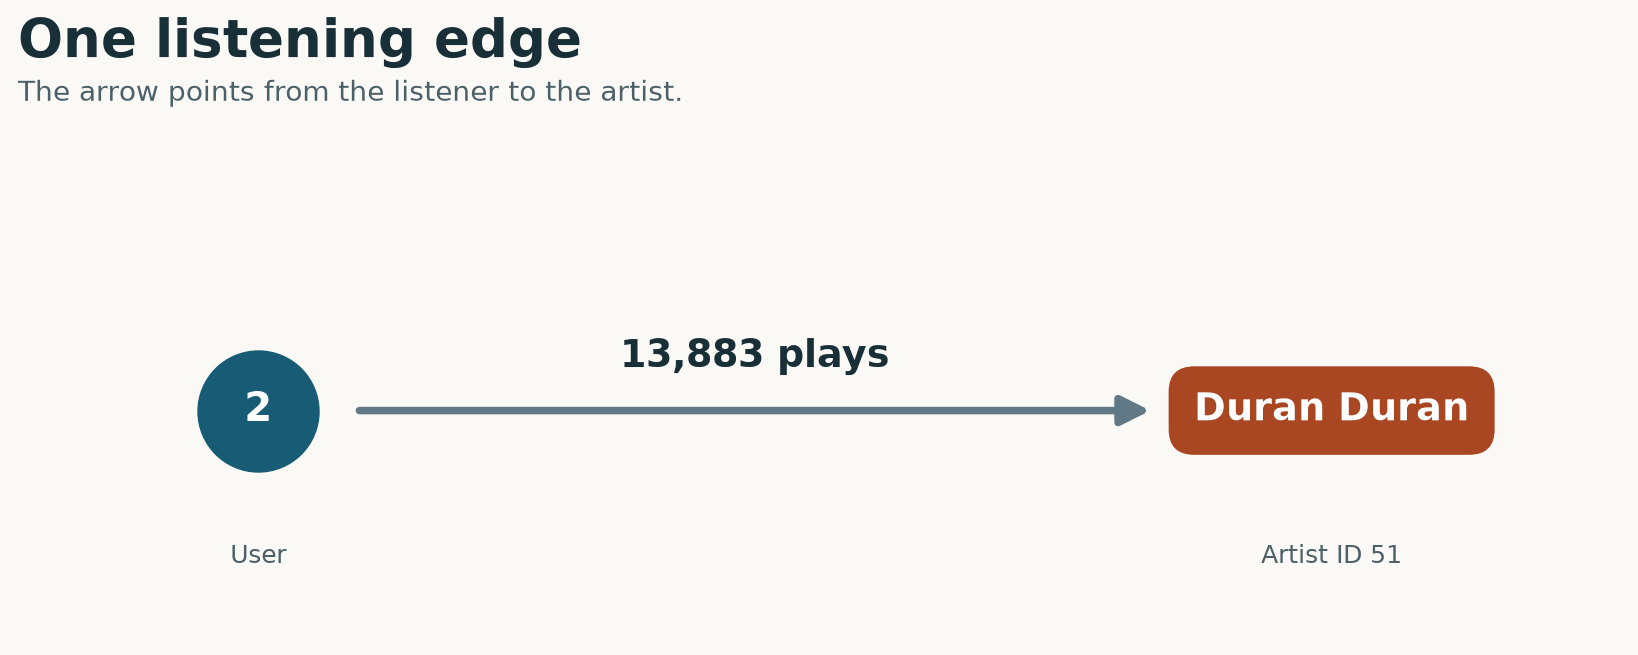

In [9]:
def draw_listening_edge(listening, artists, user=2, artist_name="Duran Duran"):
    """Draw the direction and play count of one observed listening edge."""
    artist_id = artists.loc[artists["name"].eq(artist_name), "id"].item()
    record = listening.loc[
        listening["userID"].eq(user) & listening["artistID"].eq(artist_id)
    ]
    if len(record) != 1:
        raise ValueError("Expected one listening record for this user and artist.")
    weight = record["weight"].item()

    fig = make_figure("One listening edge", "The arrow points from the listener to the artist.", (10, 4.1))
    ax = fig.add_axes([.055, .10, .89, .59], xlim=(0, 1), ylim=(0, 1))
    ax.set_axis_off()
    ax.scatter(.15, .52, s=2300, color=USER_COLOR)
    ax.text(.15, .52, str(user), color="white", ha="center", va="center", weight="bold", fontsize=16)
    ax.annotate("", xy=(.71, .52), xytext=(.21, .52),
                arrowprops=dict(arrowstyle="-|>", lw=3, color=LISTENING_COLOR, mutation_scale=24))
    ax.text(.46, .62, f"{format_count(weight)} plays", ha="center", color=TEXT_COLOR, fontsize=15, weight="bold")
    ax.text(.82, .52, artist_name, ha="center", va="center", color="white", fontsize=15, weight="bold",
            bbox=dict(boxstyle="round,pad=.68", facecolor=ARTIST_COLOR, edgecolor="none"))
    ax.text(.15, .17, "User", ha="center", color=SECONDARY_COLOR)
    ax.text(.82, .17, f"Artist ID {artist_id}", ha="center", color=SECONDARY_COLOR)
    return fig

user_id = 2
artist_name = "Duran Duran"
show_figure(draw_listening_edge(listening, artists, user_id, artist_name), "01_listening_edge")

### 2 · The eight nodes in the project proposal
Identify two users who listened to the same artist. The two arrows establish shared listening. A separate friendship edge establishes whether the users are connected socially. The four artists shown form an illustrative subset.

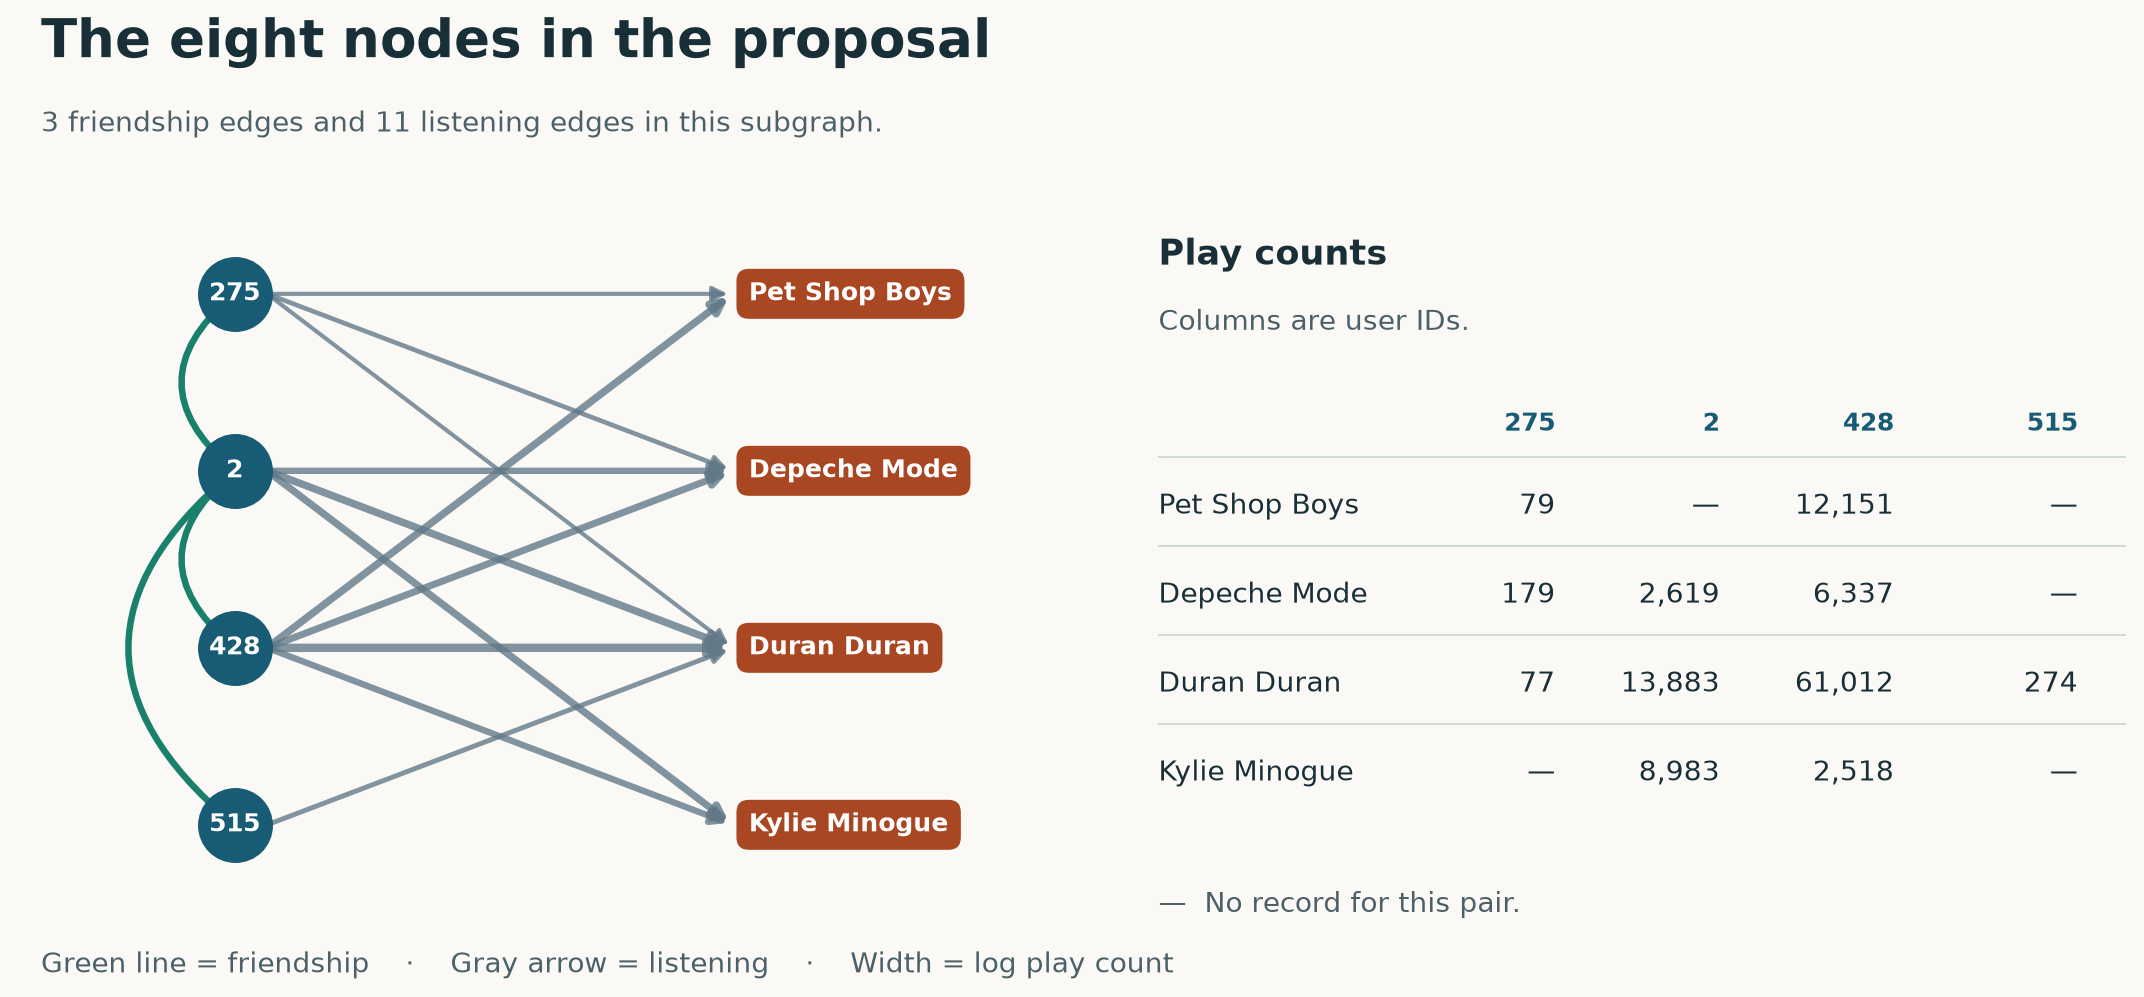

In [10]:
def draw_proposal_subgraph(listening, artists, friendships):
    """Draw all observed edges among the eight nodes in the proposal."""
    users = [275, 2, 428, 515]
    names = ["Pet Shop Boys", "Depeche Mode", "Duran Duran", "Kylie Minogue"]
    artist_id = artists.set_index("name")["id"].loc[names]
    subset = listening.loc[
        listening["userID"].isin(users) & listening["artistID"].isin(artist_id)
    ]
    social_graph = nx.from_pandas_edgelist(friendships, "userID", "friendID")
    edges = social_graph.subgraph(users).edges
    fig = make_figure("The eight nodes in the proposal",
                 f"{len(edges)} friendship edges and {len(subset)} listening edges in this subgraph.",
                 (12.8, 6.1))
    ax = fig.add_axes([.045, .13, .47, .62], xlim=(0, 1), ylim=(0, 1))
    ax.set_axis_off()
    y = [.90, .64, .38, .12]
    user_y = dict(zip(users, y))
    artist_y = dict(zip(artist_id, y))

    for u, v in edges:
        upper, lower = sorted((user_y[u], user_y[v]), reverse=True)
        ax.add_patch(FancyArrowPatch((.20, upper), (.20, lower), connectionstyle="arc3,rad=.60",
                                     arrowstyle="-", color=FRIEND_COLOR, linewidth=2.6))
    for row in subset.itertuples(index=False):
        # Use logarithmic widths to keep low and high play counts visible together.
        width = .5 + .60 * math.log10(1 + row.weight)
        ax.add_patch(FancyArrowPatch((.23, user_y[row.userID]), (.66, artist_y[row.artistID]),
                                     arrowstyle="-|>", mutation_scale=12, linewidth=width,
                                     color=LISTENING_COLOR, alpha=.79))
    for u, h in user_y.items():
        ax.scatter(.20, h, s=840, color=USER_COLOR, zorder=3)
        ax.text(.20, h, str(u), color="white", weight="bold", ha="center", va="center", zorder=4)
    for name, h in zip(names, y):
        ax.text(.675, h, name, ha="left", va="center", color="white", weight="bold",
                bbox=dict(boxstyle="round,pad=.50", facecolor=ARTIST_COLOR, edgecolor="none"))

    table_ax = fig.add_axes([.54, .18, .42, .54], xlim=(0, 1), ylim=(0, 1))
    table_ax.set_axis_off()
    table_ax.text(0, .99, "Play counts", color=TEXT_COLOR, weight="bold", fontsize=14)
    table_ax.text(0, .88, "Columns are user IDs.", color=SECONDARY_COLOR, fontsize=11)
    matrix = subset.pivot(index="artistID", columns="userID", values="weight").reindex(
        index=artist_id, columns=users)
    xs = [.41, .58, .76, .95]
    for x, u in zip(xs, users):
        table_ax.text(x, .71, str(u), ha="right", color=USER_COLOR, weight="bold")
    for i, (name, (_, row)) in enumerate(zip(names, matrix.iterrows())):
        h = .57 - i * .15
        table_ax.axhline(h + .095, color="#D2DAD8", lw=.8)
        table_ax.text(0, h, name, color=TEXT_COLOR, fontsize=11)
        for x, value in zip(xs, row):
            table_ax.text(x, h, "—" if math.isnan(value) else format_count(value),
                          ha="right", fontsize=11, color=TEXT_COLOR)
    fig.text(.055, .07, "Green line = friendship    ·    Gray arrow = listening    ·    Width = log play count",
             color=SECONDARY_COLOR, fontsize=11)
    fig.text(.54, .125, "—  No record for this pair.", color=SECONDARY_COLOR, fontsize=11)
    return fig

show_figure(draw_proposal_subgraph(listening, artists, friendships), "02_proposal_subgraph")

### 3 · User 2’s friendship neighborhood
We select the focal user, all direct friends, and every recorded friendship among those users. When two of the focal user’s friends are themselves friends, the three users form a triangle.

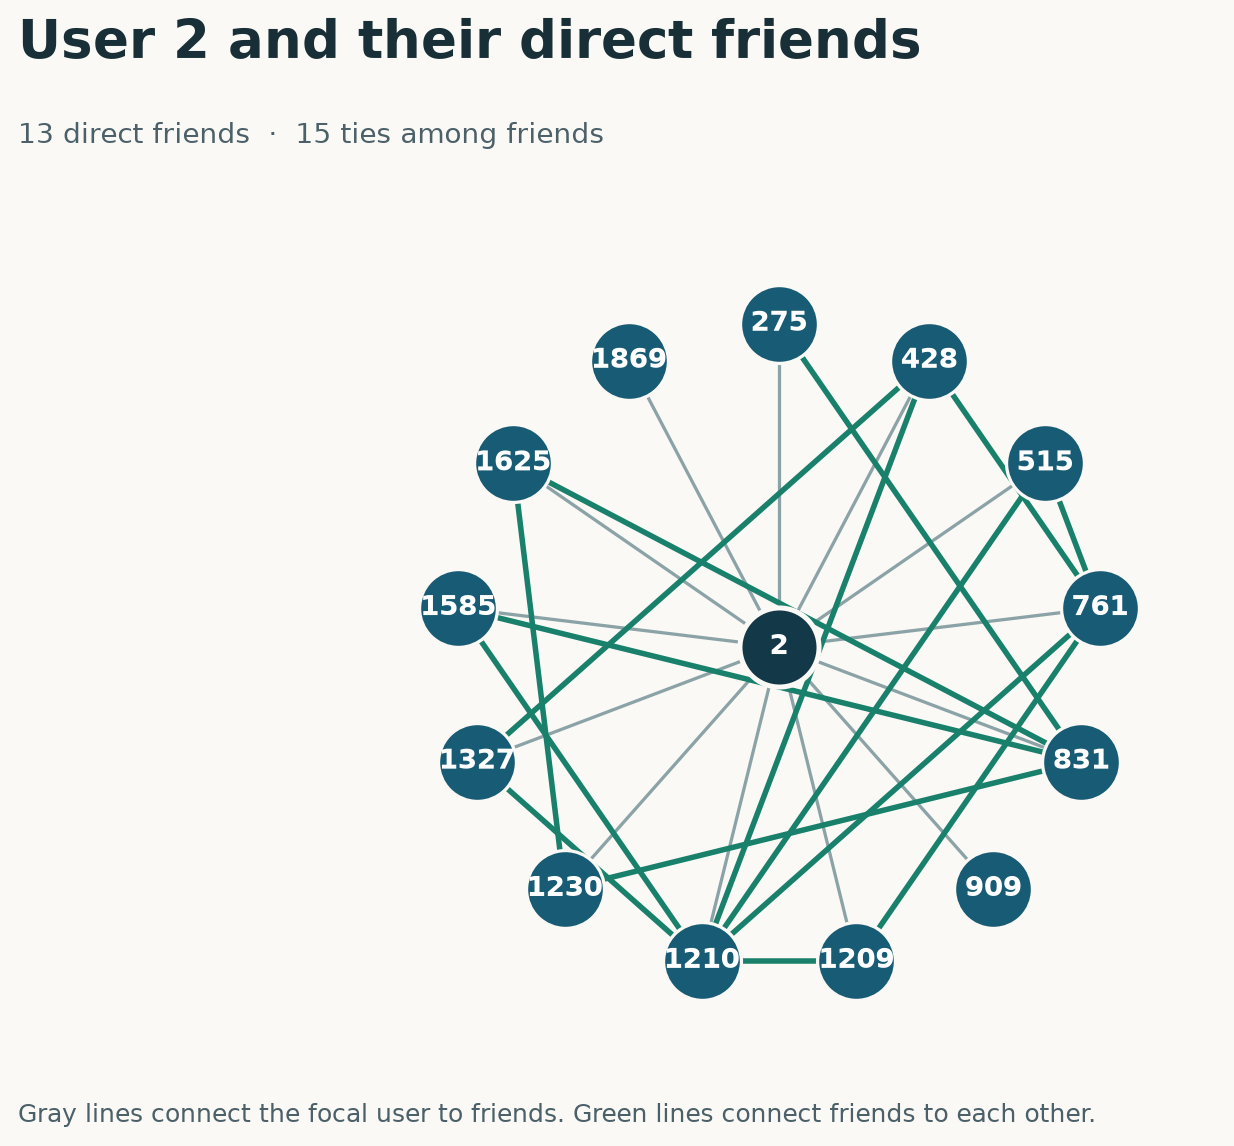

In [11]:
def draw_ego_network(friendships, user=2):
    """Draw the user, all direct friends, and friendships among them."""
    graph = nx.from_pandas_edgelist(friendships, "userID", "friendID")
    ego_graph = nx.ego_graph(graph, user, radius=1)
    neighbors = sorted(graph.neighbors(user))
    neighbor_edges = list(ego_graph.subgraph(neighbors).edges)
    positions = {user: (0, 0)}
    for i, u in enumerate(neighbors):
        angle = math.pi / 2 - 2 * math.pi * i / len(neighbors)
        positions[u] = (math.cos(angle), math.sin(angle))
    fig = make_figure(f"User {user} and their direct friends",
                 f"{len(neighbors)} direct friends  ·  {len(neighbor_edges)} ties among friends",
                 (9.5, 6.8))
    ax = fig.add_axes([.07, .075, .86, .71])
    ax.set_aspect("equal")
    ax.set_axis_off()
    nx.draw_networkx_edges(ego_graph, positions, edgelist=[(user, u) for u in neighbors],
                           edge_color="#8BA3A7", width=1.3, ax=ax)
    nx.draw_networkx_edges(ego_graph, positions, edgelist=neighbor_edges,
                           edge_color=FRIEND_COLOR, width=2.2, ax=ax)
    nx.draw_networkx_nodes(ego_graph, positions, nodelist=neighbors, node_color=USER_COLOR,
                          node_size=970, edgecolors=BACKGROUND, linewidths=1.3, ax=ax)
    nx.draw_networkx_nodes(ego_graph, positions, nodelist=[user], node_color="#133847",
                          node_size=1000, edgecolors=BACKGROUND, linewidths=2, ax=ax)
    nx.draw_networkx_labels(ego_graph, positions, font_color="white", font_weight="bold", font_size=11, ax=ax)
    ax.margins(.12)
    fig.text(.055, .038, "Gray lines connect the focal user to friends. Green lines connect friends to each other.",
             color=SECONDARY_COLOR, fontsize=10)
    return fig

focal_user = 2
show_figure(draw_ego_network(friendships, focal_user), "03_friendship_neighborhood")

### 4 · Artists shared by two friends
We now use the **complete recorded profiles** of users 2 and 428. The diagram shows the artists in their intersection. The denominator of the Jaccard coefficient counts all distinct artists in the union of the two profiles.

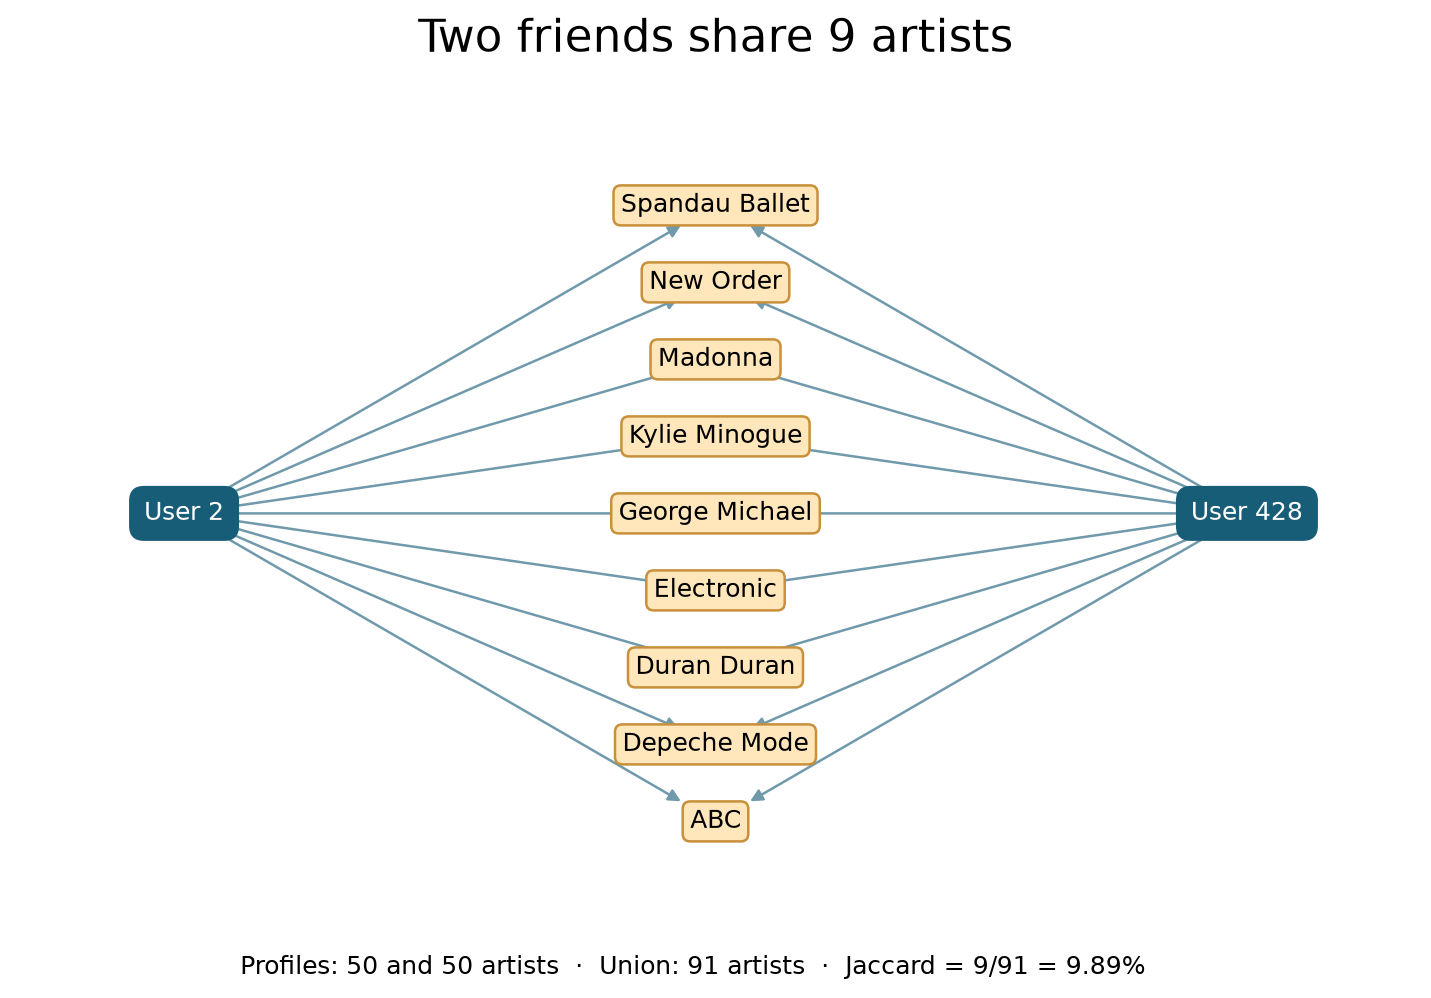

In [12]:
u, v = 2, 428
def listening_profile(user):
    return set(listening.loc[listening.userID.eq(user), "artistID"])

p, q = listening_profile(u), listening_profile(v)
names = artists.set_index("id").name
shared_artists = sorted(p & q, key=lambda a: names[a])
fig, ax = plt.subplots(figsize=(10, 6))
ax.set(xlim=(-2.1, 2.1), ylim=(-1, len(shared_artists)+0.8))
center = (len(shared_artists)-1)/2
for i, a in enumerate(shared_artists):
    for x in [-1.6, 1.6]:
        ax.annotate("", xy=(0, i), xytext=(x, center),
                    arrowprops=dict(arrowstyle="-|>", shrinkA=18, shrinkB=16, color="#709aac"))
    ax.text(0, i, names[a], ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.30", fc="#ffe6bb", ec="#c8903a"))
for x, user in [(-1.6,u),(1.6,v)]:
    ax.text(x, center, f"User {user}", ha="center", va="center", color="white",
            bbox=dict(boxstyle="round,pad=0.6", fc="#185d78", ec="none"))
ax.set_title(f"Two friends share {len(shared_artists)} artists", fontsize=18)
ax.set_xlabel("")
ax.axis("off")
fig.text(0.5, 0.04, f"Profiles: {len(p)} and {len(q)} artists  ·  Union: {len(p|q)} artists  ·  Jaccard = {len(shared_artists)}/{len(p|q)} = {100*len(shared_artists)/len(p|q):.2f}%", ha="center")
show_figure(fig, "04_shared_artists")

### Does the pattern extend to all user pairs?
The next cell considers every unordered pair of distinct users exactly once. Each profile is the set of artists that the user listened to. For each pair, we divide the number of shared artists by the number of distinct artists in either profile. This is an exhaustive comparison of the recorded users.

In [13]:
users, row = np.unique(listening.userID, return_inverse=True)
artist_id, column = np.unique(listening.artistID, return_inverse=True)
M = csr_matrix((np.ones(len(row), dtype=int), (row, column)))
left, right = np.triu_indices(len(users), k=1)
intersection_size = (M @ M.T).toarray()[left, right]
size = np.asarray(M.sum(axis=1)).ravel()
jaccard = intersection_size / (size[left] + size[right] - intersection_size)
adjacency = nx.to_numpy_array(G, nodelist=users.tolist(), dtype=bool)
friend_mask = adjacency[left, right]
result = pd.DataFrame([{"Pair type": name, "Pairs": int(mask.sum()),
                       "Mean": jaccard[mask].mean(), "Median": np.median(jaccard[mask])}
                      for name, mask in [("Friends", friend_mask), ("No recorded friendship", ~friend_mask)]])
display(result.round(4))
print(f"Mean Jaccard ratio: {result.Mean[0]/result.Mean[1]:.2f}")

,Pair type,Pairs,Mean,Median
0,Friends,12717,0.1026,0.0870
1,No recorded friendship,1776169,0.0236,0.0101


Mean Jaccard ratio: 4.34


**Interpretation.** Friends have higher mean Jaccard similarity in this sample. Artist popularity may account for part of the observed difference. A degree-preserving permutation test could assess how much overlap to expect given each user’s profile size and each artist’s listener count. Users occur in multiple pairs, so a significance test that assumes independent pairs may give misleading results.

## From communities to the full network
Louvain identifies groups with a concentration of internal friendship edges relative to a degree-based reference model. The resulting communities form a partition inferred from the observed network. They carry no intrinsic genre labels or self-reported group memberships. A fixed random seed supports reproducibility in the same software environment.

In [14]:
INK = "#172c40"
MUTED = "#476073"
SOCIAL = "#156754"
ARTIST = "#c56527"
PALETTE = ["#15736c", "#7353a1", "#c97327", "#3e70a9", "#ad496b", "#849a38", "#927451"]
OTHER = "#82939e"


def _number(value):
    return f"{value:,}"


def _color(group):
    return PALETTE[group - 1] if 1 <= group <= len(PALETTE) else OTHER


def _canvas(title, subtitle):
    fig = plt.figure(figsize=(12.8, 7.3), facecolor="white")
    chart = fig.add_axes([0.035, 0.07, 0.64, 0.77], aspect="equal")
    key = fig.add_axes([0.707, 0.07, 0.27, 0.76], xlim=(0, 1), ylim=(0, 1))
    for ax in (chart, key):
        ax.set_axis_off()
    fig.text(0.045, 0.92, title, fontsize=24, fontweight="bold", color=INK)
    fig.text(0.045, 0.865, subtitle, fontsize=12, color=MUTED)
    return fig, chart, key


def _note(ax, y, text, size=10.5, color=MUTED, bold=False):
    ax.text(0, y, text, va="top", fontsize=size, color=color,
            fontweight="bold" if bold else "normal", linespacing=1.5)


def _draw_edges(ax, edges, pos, color, width, alpha):
    if len(edges):
        ax.add_collection(LineCollection(
            [[pos[u], pos[v]] for u, v in edges], colors=color,
            linewidths=width, alpha=alpha, zorder=1, rasterized=True,
        ))


def _components_layout(graph, seed=42, iterations=55):
    """Place the largest component on the left and smaller components on the right."""
    parts = sorted(nx.connected_components(graph), key=lambda s: (-len(s), min(s)))
    core = graph.subgraph(parts[0])
    pos = nx.spring_layout(core, seed=seed, iterations=iterations)
    if len(parts) > 1:
        columns = max(1, int(np.ceil(np.sqrt((len(parts) - 1) / 2))))
        rows = int(np.ceil((len(parts) - 1) / columns))
        for i, members in enumerate(parts[1:]):
            center = np.array([1.18 + 0.18 * (i % columns), 0.83 - 1.66 * (i // columns) / max(rows - 1, 1)])
            small = nx.spring_layout(graph.subgraph(members), seed=seed, scale=0.055)
            pos.update({v: center + point for v, point in small.items()})
    return pos

In [15]:
def detect_communities(G, seed=42):
    """Partition friendships with Louvain. C1 is the largest community."""
    groups = nx.community.louvain_communities(G, seed=seed, weight=None)
    groups = sorted(groups, key=lambda members: (-len(members), min(members)))
    return {user: group for group, members in enumerate(groups, 1) for user in members}

membership = detect_communities(G, seed=42)
groups = {}
for user, group in membership.items():
    groups.setdefault(group, set()).add(user)
print(f"{len(groups)} communities | Modularity: {nx.community.modularity(G, groups.values()):.3f}")

34 communities | Modularity: 0.458


### 5 · Which friendship communities listen to an artist?
We count each listener of Duran Duran once. The central node represents the artist, and the surrounding nodes represent friendship communities. An edge label counts the artist’s listeners in that community. The figure illustrates the idea of an artist reaching across communities. Ranking such artists requires a comparison that accounts for audience size and the sizes of the communities.

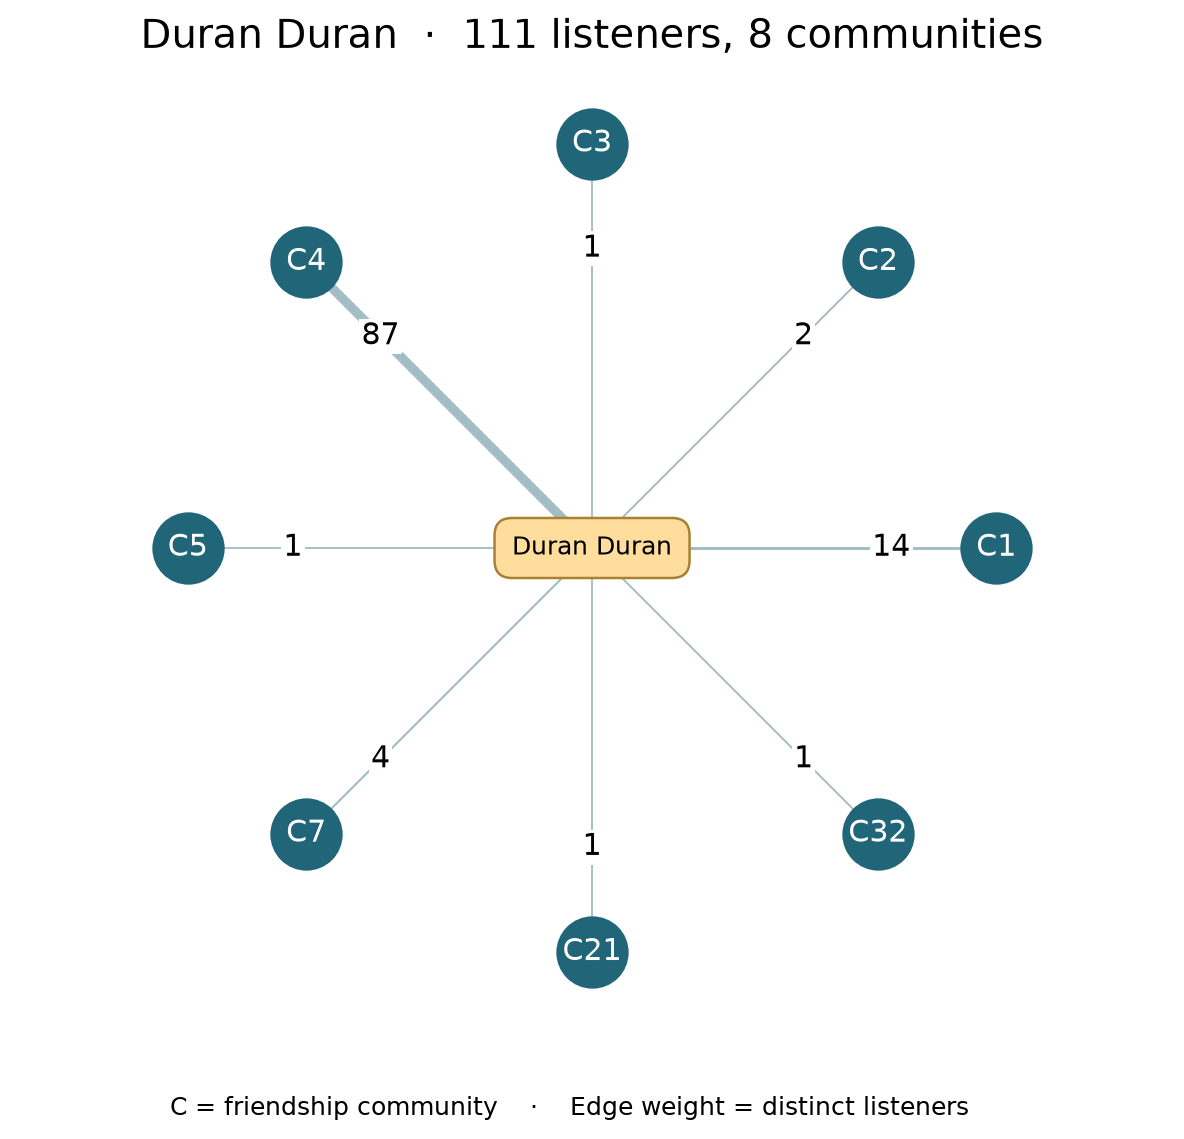

In [16]:
artist = "Duran Duran"
artist_id = artists.loc[artists.name.eq(artist), "id"].item()
listeners = listening.loc[listening.artistID.eq(artist_id), "userID"]
listener_counts = listeners.map(membership).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 7))
ax.set(xlim=(-1.42,1.42), ylim=(-1.2,1.2), aspect="equal")
for i, (group, count) in enumerate(listener_counts.items()):
    angle = 2*np.pi*i/len(listener_counts)
    x, y = np.cos(angle), np.sin(angle)
    ax.plot([0,x],[0,y], c="#a2bdc3", lw=0.7+3*count/listener_counts.max(), zorder=0)
    ax.scatter(x, y, s=780, color="#206578", zorder=2)
    ax.text(x,y,f"C{group}",ha="center",va="center",color="white",fontsize=12)
    ax.text(0.74*x,0.74*y,str(count),ha="center",va="center",fontsize=12,
            bbox=dict(facecolor="white",edgecolor="none",pad=1))
ax.text(0,0,artist,ha="center",va="center",bbox=dict(boxstyle="round,pad=0.7",fc="#ffde9d",ec="#aa8032"))
ax.axis("off")
ax.set_title(f"{artist}  ·  {len(listeners)} listeners, {len(listener_counts)} communities", fontsize=16)
fig.text(0.5,0.045,"C = friendship community    ·    Edge weight = distinct listeners",ha="center")
show_figure(fig, "05_artist_audience_by_community")

### 6 · Friendships between communities
Each node now represents an entire community. The weight of an edge is the number of friendships connecting its two communities. Aggregation reveals which pairs of groups share the most ties.

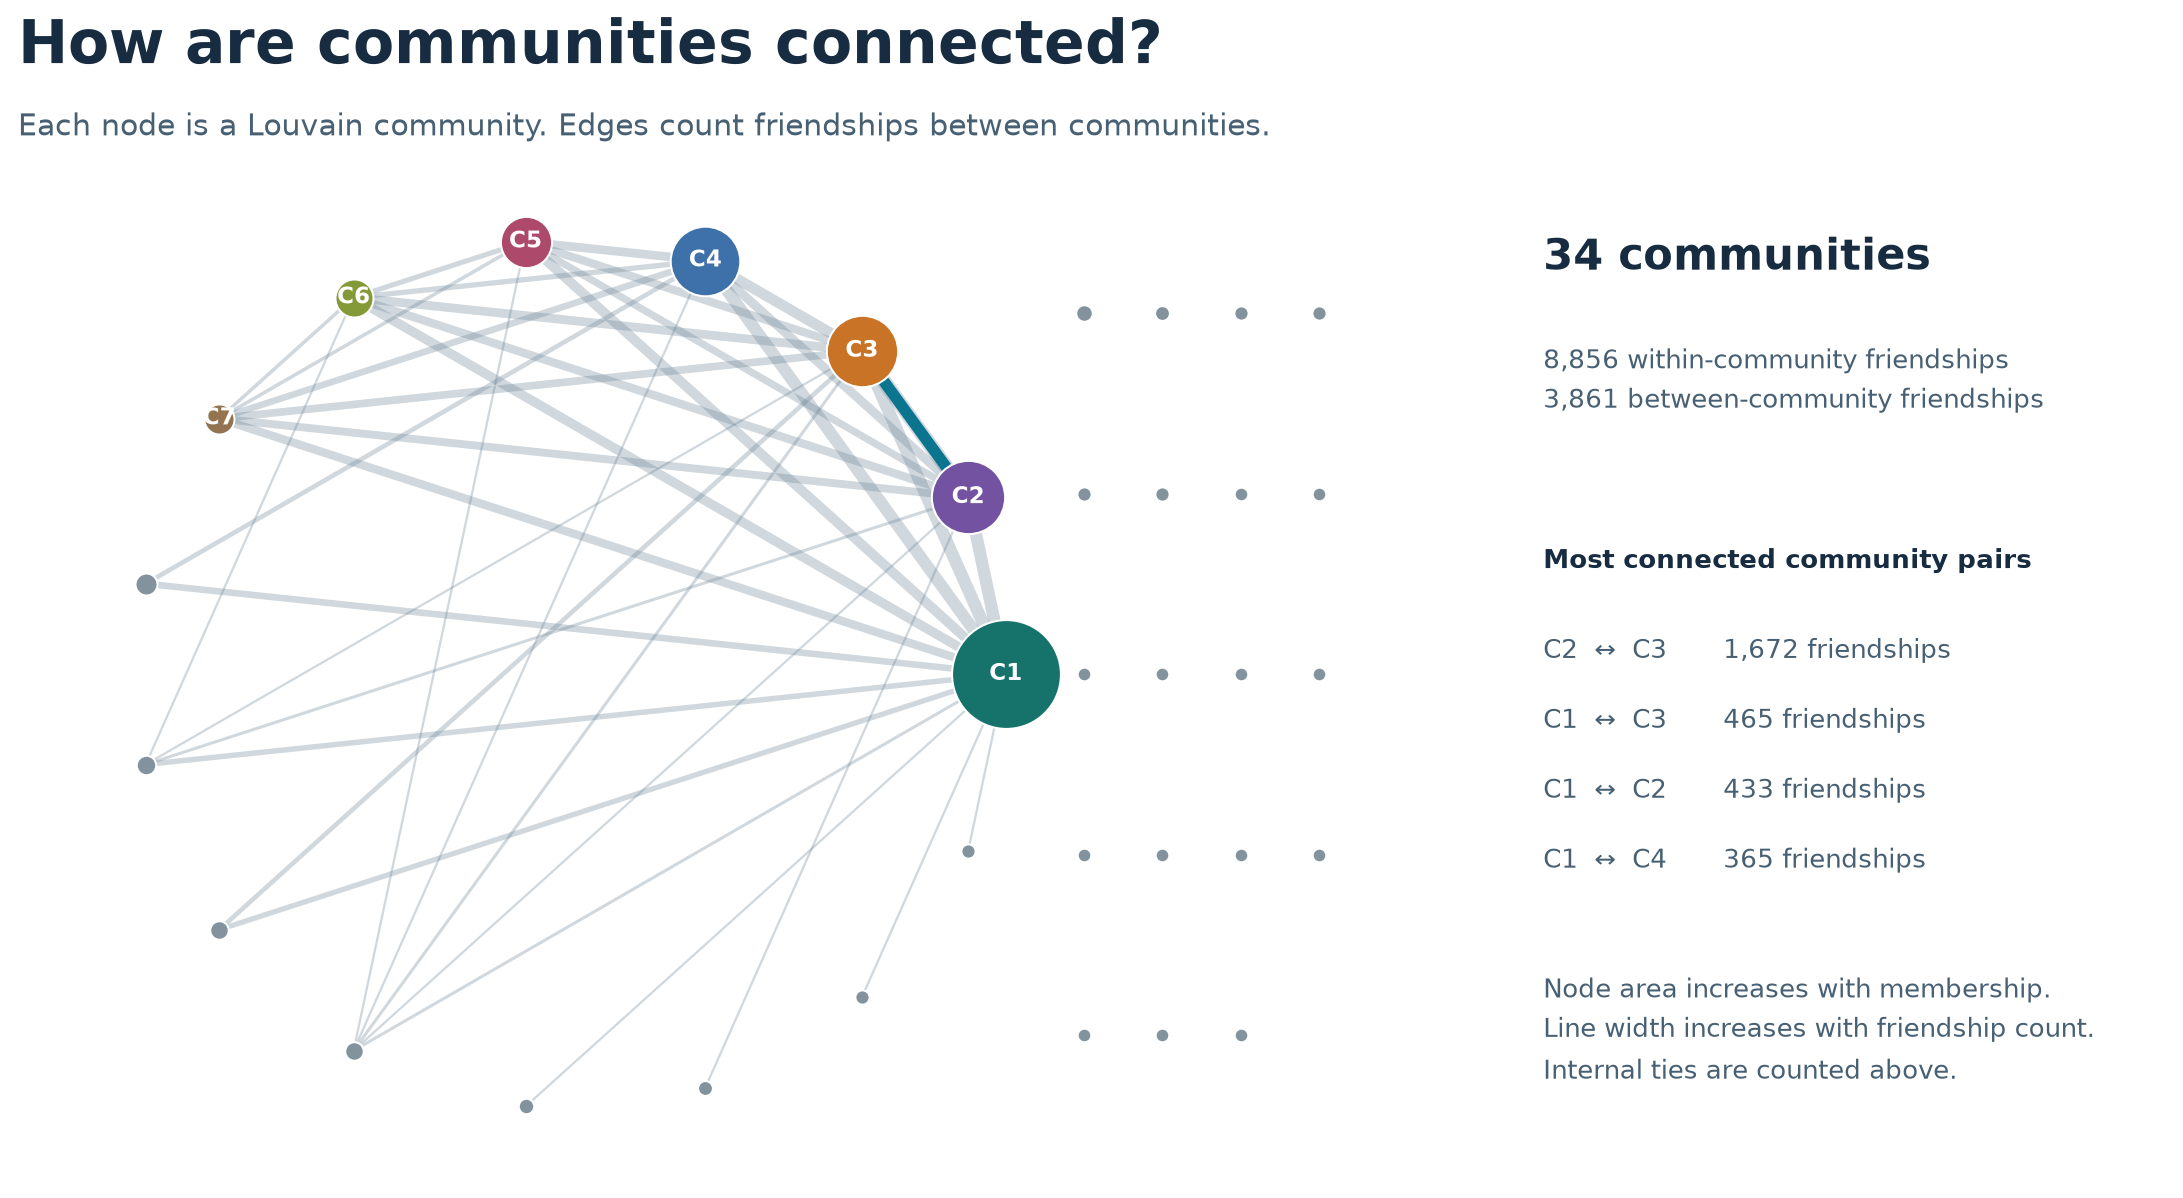

In [17]:
def draw_community_network(G, membership):
    """Aggregate communities. Each edge counts friendships between two groups."""
    sizes = pd.Series(membership).value_counts()
    aggregate = nx.Graph()
    aggregate.add_nodes_from(sorted(sizes.index))
    internal = 0
    for u, v in G.edges:
        a, b = membership[u], membership[v]
        if a == b:
            internal += 1
        elif aggregate.has_edge(a, b):
            aggregate[a][b]["weight"] += 1
        else:
            aggregate.add_edge(a, b, weight=1)
    fig, ax, key = _canvas("How are communities connected?",
                           "Each node is a Louvain community. Edges count friendships between communities.")
    # A circular layout separates the larger nodes and their labels.
    pos = _components_layout(aggregate)
    core = max(nx.connected_components(aggregate), key=len)
    pos.update(nx.circular_layout(sorted(core)))
    edges = sorted(aggregate.edges, key=lambda e: aggregate.edges[e]["weight"])
    top = list(reversed(edges[-4:]))
    widths = [0.4 + 0.75 * np.log1p(aggregate.edges[e]["weight"]) for e in edges]
    _draw_edges(ax, edges, pos, "#668193", widths, 0.30)
    _draw_edges(ax, top[:1], pos, "#006f8a", 4.5, 0.95)
    for group in aggregate:
        x, y = pos[group]
        ax.scatter(x, y, s=24 + 2.8 * sizes[group], c=_color(group), edgecolor="white",
                   linewidth=0.8, zorder=3)
        if group <= len(PALETTE):
            ax.annotate(f"C{group}", (x, y), xytext=(0, 0), textcoords="offset points",
                        ha="center", va="center", fontsize=9, color="white", fontweight="bold", zorder=4)
    ax.margins(0.085)
    _note(key, 0.96, f"{len(sizes)} communities", size=17, color=INK, bold=True)
    _note(key, 0.84, f"{_number(internal)} within-community friendships\n{_number(G.number_of_edges() - internal)} between-community friendships")
    _note(key, 0.64, "Most connected community pairs", color=INK, bold=True)
    for i, (a, b) in enumerate(top):
        _note(key, 0.55 - i * 0.07, f"C{min(a,b)}  ↔  C{max(a,b)}       {_number(aggregate[a][b]['weight'])} friendships")
    _note(key, 0.21, "Node area increases with membership.\nLine width increases with friendship count.\nInternal ties are counted above.")
    return fig

show_figure(draw_community_network(G, membership), "06_intercommunity_friendships")

### 7 · The complete friendship network
Each node again represents one user. In the proposal, this social layer supplies the edges for centrality analysis, link prediction, and user embeddings. Distinct colors identify the largest communities. Gray denotes the remaining communities.

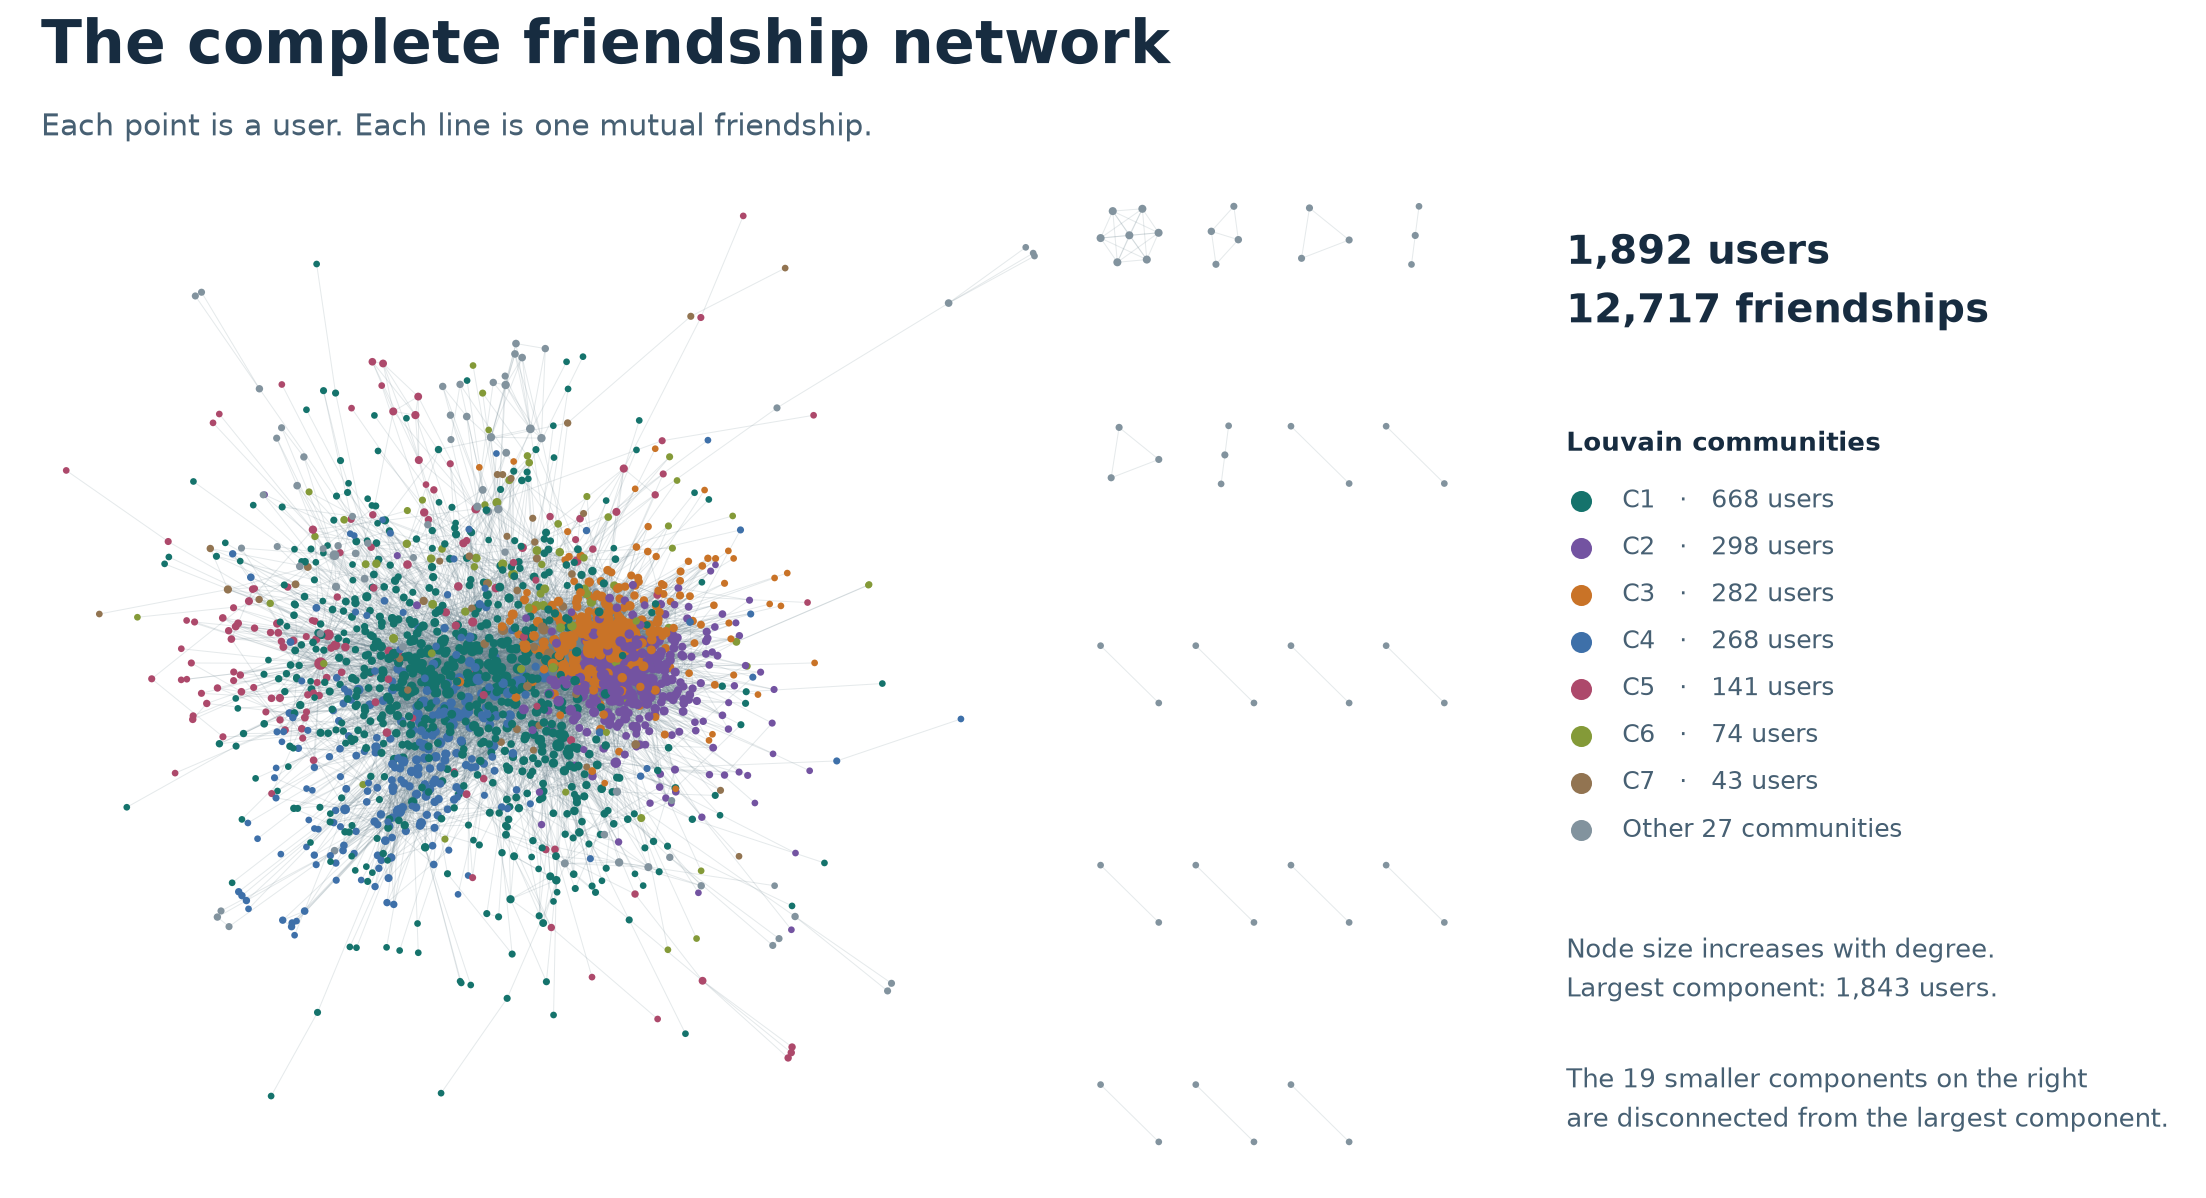

In [18]:
def draw_friendship_network(G, membership):
    """Draw each user and each undirected friendship once."""
    fig, ax, key = _canvas("The complete friendship network",
                           "Each point is a user. Each line is one mutual friendship.")
    pos = _components_layout(G)
    _draw_edges(ax, list(G.edges), pos, "#68808b", 0.40, 0.17)
    users = list(G.nodes)
    points = np.array([pos[u] for u in users])
    ax.scatter(*points.T, s=[5 + 2.2 * np.sqrt(G.degree(u)) for u in users],
               c=[_color(membership[u]) for u in users], linewidths=0, zorder=2, rasterized=True)
    ax.margins(0.035)
    sizes = pd.Series(membership).value_counts()
    components = list(nx.connected_components(G))
    _note(key, 0.96, f"{_number(len(G))} users\n{_number(G.number_of_edges())} friendships",
          size=16, color=INK, bold=True)
    _note(key, 0.76, "Louvain communities", color=INK, bold=True)
    for group in range(1, min(len(sizes), len(PALETTE)) + 1):
        y = 0.68 - 0.047 * (group - 1)
        key.scatter(0.024, y, s=55, color=_color(group))
        key.text(0.09, y, f"C{group}   ·   {_number(sizes[group])} users", va="center", color=MUTED)
    extra = sizes[sizes.index > len(PALETTE)]
    if len(extra):
        key.scatter(0.024, 0.35, s=55, color=OTHER)
        key.text(0.09, 0.35, f"Other {len(extra)} communities", va="center", color=MUTED)
    _note(key, 0.25, f"Node size increases with degree.\nLargest component: {_number(max(map(len, components)))} users.")
    if len(components) > 1:
        _note(key, 0.12, f"The {len(components) - 1} smaller components on the right\nare disconnected from the largest component.")
    return fig

show_figure(draw_friendship_network(G, membership), "07_friendship_network", vector=False)

### Explore a neighborhood by user ID
Open the link in a browser. Enter a **User ID** and select **Focus**. The mouse wheel zooms around the pointer. Selecting a node makes that person the focal user. The view includes the focal user, all direct friends, and the friendships among them.

In [19]:
import json
from IPython.display import Markdown

neighbors_by_user = {int(user): sorted(map(int, G.neighbors(user))) for user in G}
page = """<!doctype html><html lang="en"><meta charset="utf-8"><title>Last.fm friendship explorer</title>
<style>body{font:16px system-ui;color:#193846;max-width:1200px;margin:24px auto;padding:0 16px}input,button{font:inherit;padding:5px}svg{width:100%;height:70vh;border:1px solid #abc;touch-action:none;background:#fafcfb}text{font:bold 11px system-ui;paint-order:stroke;stroke:white;stroke-width:3;fill:#193846;pointer-events:none}circle{cursor:pointer}#status{margin:10px 0}</style>
<h1>Friendship explorer</h1><form id="form"><label>User ID <input id="uid" type="number" value="2" required></label> <button>Focus</button> <button type="button" id="reset">Fit network</button></form><p>Scroll at a node to zoom. Drag the background to pan. Click a user to explore their friends.</p><div id="status" role="status"></div><svg id="network" aria-label="Friendship network"></svg>
<script>
const friends = __ADJACENCY__;
const svg = document.querySelector('svg'), input = document.querySelector('#uid'), statusLine = document.querySelector('#status');
let view, home, drag;
function setView(box){view=box;svg.setAttribute('viewBox',box.join(' '));}
function point(event){return new DOMPoint(event.clientX,event.clientY).matrixTransform(svg.getScreenCTM().inverse());}
function add(tag,attrs){const el=document.createElementNS(svg.namespaceURI,tag);for(const [k,v] of Object.entries(attrs))el.setAttribute(k,v);svg.append(el);return el;}
function focusUser(id){
 const neighbors=friends[id];if(!neighbors){statusLine.textContent='Unknown user ID: '+id;return;}
 svg.replaceChildren();input.value=id;const radius=Math.max(125,neighbors.length*8);
 const positions=new Map([[id,[0,0]]]);neighbors.forEach((u,i)=>{const a=2*Math.PI*i/neighbors.length;positions.set(u,[radius*Math.cos(a),radius*Math.sin(a)]);});
 for(const [u,[x1,y1]] of positions)for(const v of friends[u])if(v>u && positions.has(v)){const [x2,y2]=positions.get(v);add('line',{x1,y1,x2,y2,stroke:u===id||v===id?'#477e92':'#bed3c8','stroke-width':1});}
 for(const [u,[x,y]] of positions){const circle=add('circle',{cx:x,cy:y,r:u===id?9:6,fill:u===id?'#ac5420':'#12667a'});circle.onclick=()=>focusUser(u);add('text',{x,y:y-10,'text-anchor':'middle'}).textContent=u;}
 const d=radius+35;home=[-d,-d,2*d,2*d];setView(home);statusLine.textContent='User '+id+' · '+neighbors.length+' direct friends';
}
document.querySelector('#form').onsubmit=e=>{e.preventDefault();focusUser(Number(input.value));};
document.querySelector('#reset').onclick=()=>setView(home);
svg.addEventListener('wheel',e=>{e.preventDefault();const p=point(e),k=Math.exp(Math.sign(e.deltaY)*0.15),w=view[2]*k;if(w<30||w>home[2]*4)return;setView([p.x+(view[0]-p.x)*k,p.y+(view[1]-p.y)*k,w,w]);},{passive:false});
svg.onpointerdown=e=>{if(e.target.tagName==='circle')return;drag=point(e);svg.setPointerCapture(e.pointerId);};
svg.onpointermove=e=>{if(!drag)return;const p=point(e);setView([view[0]+drag.x-p.x,view[1]+drag.y-p.y,view[2],view[3]]);};
svg.onpointerup=svg.onpointercancel=()=>{drag=null;};
focusUser(2);
</script></html>"""
explorer_path = project / "outputs" / "friendship_explorer.html"
explorer_path.parent.mkdir(parents=True, exist_ok=True)
explorer_path.write_text(page.replace("__ADJACENCY__", json.dumps(neighbors_by_user)), encoding="utf-8")
display(Markdown("[Open the friendship explorer](outputs/friendship_explorer.html)"))

[Open the friendship explorer](outputs/friendship_explorer.html)

### 8 · Two node types and two edge types
The complete heterogeneous graph combines friendship edges between users with listening edges from users to artists. The first two figures help trace individual edges. The full-network view shows how the same users connect the two layers.

For a readable neighborhood during a presentation, change the focal user in **Figure 3**. Edges overlap at full scale. Users are grouped around the ring by friendship community, and each artist is placed in the sector containing the largest number of that artist’s listeners.

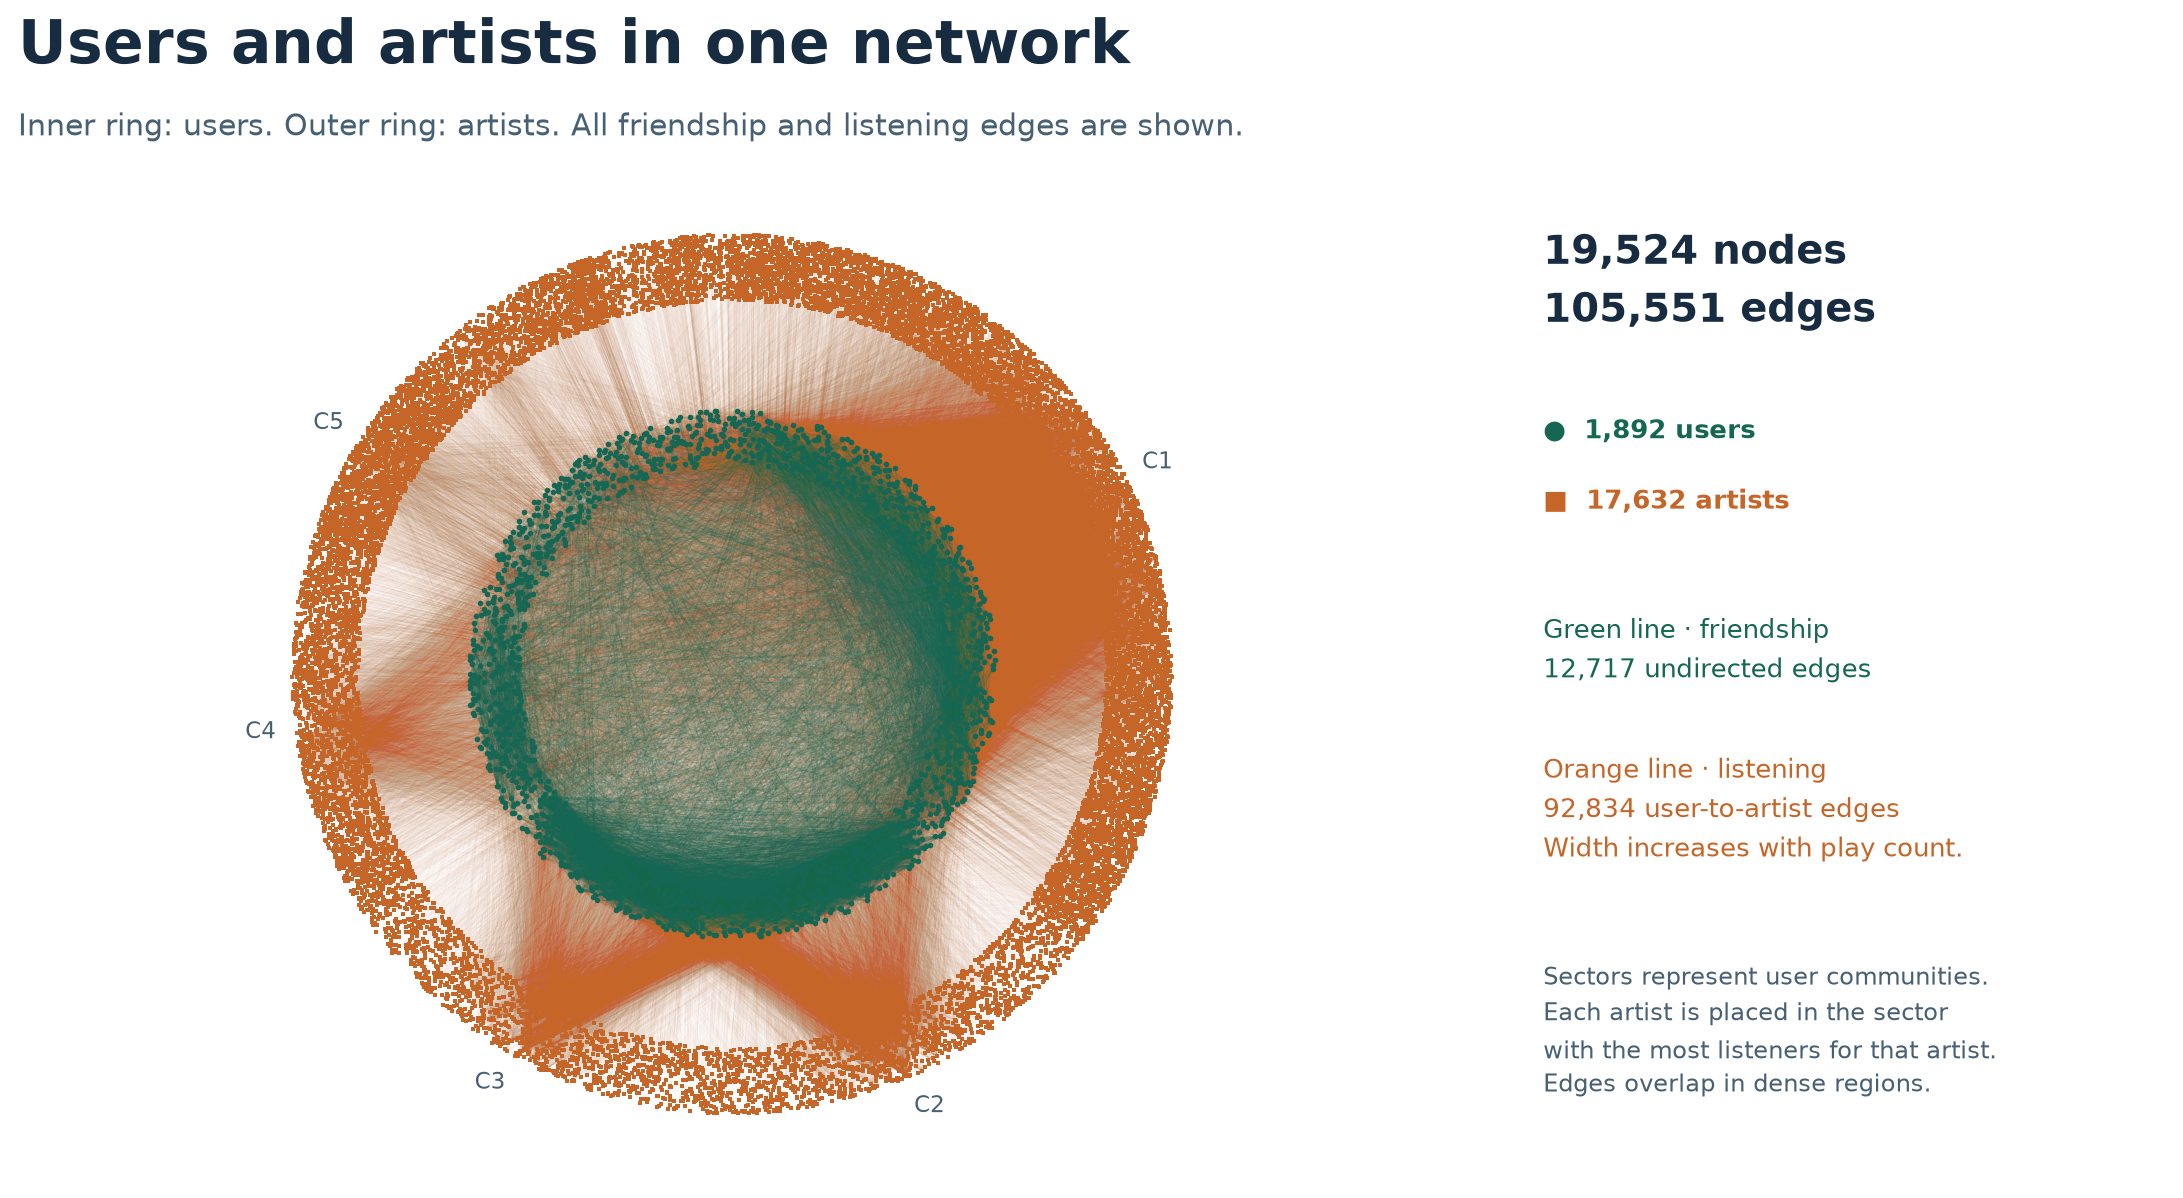

In [20]:
def draw_heterogeneous_network(G, membership, listening):
    """Draw all friendship and listening edges using separate node rings."""
    # Use separate indices for users and artists to avoid ID collisions.
    users = sorted(G, key=lambda u: (membership[u], u))
    user_idx = pd.Index(users)
    artist_idx = pd.Index(np.sort(listening.artistID.unique()))
    row = user_idx.get_indexer(listening.userID)
    if np.any(row < 0):
        raise ValueError("Every listener must be present in the friendship graph.")
    col = artist_idx.get_indexer(listening.artistID)
    group = np.array([membership[u] for u in users])
    votes = pd.DataFrame({"artist": col, "group": group[row], "listener_order": row})
    counts = votes.groupby(["artist", "group"]).agg(
        listeners=("listener_order", "size"), mean_order=("listener_order", "mean")).reset_index()
    dominant = counts.sort_values(["listeners", "group"], ascending=[False, True]).drop_duplicates("artist")
    # Place each artist in the sector containing the largest number of their listeners.
    # Sector angles are proportional to community size.
    dominant = dominant.sort_values(["group", "mean_order", "artist"])
    turn = 2 * np.pi
    user_angle = np.pi / 2 - turn * (np.arange(len(users)) + 0.5) / len(users)
    artist_angle = np.empty(len(artist_idx))
    for cluster, rows in dominant.groupby("group"):
        member_idx = np.flatnonzero(group == cluster)
        fractional = (np.arange(len(rows)) + 0.5) / len(rows)
        artist_angle[rows.artist] = np.pi / 2 - turn * (member_idx[0] + fractional * len(member_idx)) / len(users)
    rng = np.random.default_rng(42)
    def ring(angles, low, high):
        radii = rng.uniform(low, high, len(angles))
        return np.column_stack((np.cos(angles) * radii, np.sin(angles) * radii))
    user_xy = ring(user_angle, 0.48, 0.60)
    artist_xy = ring(artist_angle, 0.85, 1.00)
    fig, ax, key = _canvas("Users and artists in one network",
                           "Inner ring: users. Outer ring: artists. All friendship and listening edges are shown.")
    segments = np.stack((user_xy[row], artist_xy[col]), axis=1)
    log_weight = np.log1p(listening.weight.to_numpy())
    ax.add_collection(LineCollection(segments, colors=ARTIST, alpha=0.024,
                                    linewidths=0.10 + 0.38 * log_weight / log_weight.max(),
                                    rasterized=True, zorder=1))
    social_segments = user_xy[user_idx.get_indexer(np.array(G.edges).ravel()).reshape(-1, 2)]
    ax.add_collection(LineCollection(social_segments, colors=SOCIAL, alpha=0.12,
                                    linewidths=0.36, rasterized=True, zorder=2))
    ax.scatter(*artist_xy.T, s=1.9, c=ARTIST, marker="s", linewidths=0, rasterized=True, zorder=3)
    ax.scatter(*user_xy.T, s=5, c=SOCIAL, linewidths=0, rasterized=True, zorder=4)
    for cluster in np.unique(group)[:5]:
        angle = np.mean(user_angle[group == cluster])
        ax.text(1.08 * np.cos(angle), 1.08 * np.sin(angle), f"C{cluster}", ha="center",
                va="center", fontsize=9, color=MUTED)
    ax.set(xlim=(-1.15, 1.15), ylim=(-1.15, 1.15))
    _note(key, 0.96, f"{_number(len(users) + len(artist_idx))} nodes\n{_number(len(listening) + G.number_of_edges())} edges",
          size=16, color=INK, bold=True)
    _note(key, 0.77, f"●  {_number(len(users))} users", color=SOCIAL, bold=True)
    _note(key, 0.70, f"■  {_number(len(artist_idx))} artists", color=ARTIST, bold=True)
    _note(key, 0.57, f"Green line · friendship\n{_number(G.number_of_edges())} undirected edges", color=SOCIAL)
    _note(key, 0.43, f"Orange line · listening\n{_number(len(listening))} user-to-artist edges\nWidth increases with play count.", color=ARTIST)
    _note(key, 0.22, "Sectors represent user communities.\nEach artist is placed in the sector\nwith the most listeners for that artist.\nEdges overlap in dense regions.", size=9.5)
    return fig

show_figure(draw_heterogeneous_network(G, membership, listening), "08_heterogeneous_network", vector=False)

## An application to social music discovery

**User need.** A newcomer may already have friends on a music platform before recording any plays. Can the platform use those social ties to offer a personalized first list of artists?

**Worked example.** We treat user 2 as a newcomer. We retain the friendship links, withhold the user’s own listening records, and count the distinct friends who listened to each candidate artist. This produces a ranking with a direct explanation for each recommendation. The next cell implements this simple rule on the observed data.

In [21]:
target = 2
friends = set(G.neighbors(target))
friend_plays = listening[listening.userID.isin(friends)]
votes = (friend_plays.groupby("artistID").userID.nunique()
         .rename("Friends who listened").reset_index())
top_five = (votes.merge(artists[["id", "name"]], left_on="artistID", right_on="id")
           .sort_values(["Friends who listened", "artistID"], ascending=[False, True])
           .head(5).rename(columns={"name": "Artist"}))
print(f"User {target}: top five recommendations from {len(friends)} friends")
display(top_five[["Artist", "Friends who listened"]].reset_index(drop=True))

User 2: top five recommendations from 13 friends


,Artist,Friends who listened
0,Depeche Mode,9
1,Duran Duran,8
2,Madonna,7
3,Simple Minds,7
4,Michael Jackson,6


**How would we evaluate the system?** We would withhold listening profiles for multiple users and compare two top-five lists for the same users. The popularity baseline ranks artists by the number of listeners in the training data. The social method ranks artists by support among a user’s friends. Precision@5 measures the proportion of the five recommendations that appear in the withheld profile. Recall@5 measures the proportion of the withheld artists recovered. A user with no known friends can receive the popularity list. The single worked example demonstrates the recommendation rule. Estimating performance requires evaluation across multiple users.

**Extensions proposed for the project.** Friend recommendation could provide a second feature. Artists with listeners across friendship communities could also help a user discover music beyond their immediate circle. Each extension calls for a separate assessment of its contribution to discovery.

## Questions for the proposal discussion

**Why use this dataset?** Listening histories and friendships share the same user identifiers. This lets us compare artist-profile similarity for friends and for pairs without a recorded friendship. “2K” refers to the approximately two thousand users in the sample.

**What are the nodes and edges?** The two node types are users and artists. Friendships form undirected, unweighted edges. Listening edges point from user to artist and carry a play count. The listening layer is bipartite. Adding friendships introduces user-to-user links. Tags supply artist features.

**Do friends influence each other’s musical tastes?** The observed association admits several explanations. Similar listeners may become friends, and friends may influence one another. Friendship formation dates are unavailable, so the evidence cannot establish which process came first.

**Why control for popularity?** Two randomly chosen users can share an artist simply because that artist attracts many listeners. We plan to reassign listening edges while preserving user profile sizes and artist listener counts, then compare the observed difference with the resulting reference distribution.

**How can the system recommend artists without a listening history?** Our cold-start scenario retains the user’s friendships and withholds their listening history. We plan to rank artists using training-set listening records from friends and users with similar network positions. Global popularity provides a fallback for users without social connections. Precision@K and Recall@K will measure how well the top K recommendations recover artists in the withheld profile.

**How will you evaluate friend recommendation?** We will withhold a subset of observed friendships and remove both source directions from the training graph. We will compute Node2Vec embeddings and structural features such as common-neighbor counts on that graph. We will score candidate pairs using musical and structural features and evaluate recovery of the withheld ties with ROC-AUC and average precision. We will report results separately for randomly selected pairs without recorded friendships and for harder negative examples whose members share a friend.

**What is a bridge artist?** An artist whose audience spans several friendship communities. The entropy of the distribution of listeners across communities can summarize that reach. Comparing artists with similar audience sizes helps address the greater reach expected for popular artists.

**What is the main data limitation?** The dataset records at most 50 artists per user, so preferences regarding unrecorded artists remain unknown. Tag coverage also varies across artists. We therefore define evaluation outcomes in terms of each user’s **recorded profile**.

**Which results are available?** We verified the source data, constructed both network layers, identified friendship communities, produced the network views, and compared unadjusted Jaccard similarity across all user pairs. Planned work includes the popularity-controlled test, training and evaluating recommendation models, and ranking bridge artists.

**A one-minute presentation.** Introduce the data source and explain why the two linked tables matter. Trace a friendship and a listening edge in Figure 2. Use Figure 4 to explain the overlap calculation, then give the all-pairs result. Show both layers together in Figure 8. Close with the next question: how much similarity remains after controlling for popularity, and does social information improve recommendations?

## Closing the presentation

“Two reciprocal source records give us one friendship edge. Play counts provide the weights on the listening edges. Shared user identifiers let us follow a user’s friendships and the artists those friends listen to.”

**Next experiment.** Withhold the listening histories of users whose friendships are known. Compare the top five artists identified through friends with the five most popular artists in the training set. Use the same users and candidate artists for both lists, and exclude the target users’ withheld records from popularity estimates. The comparison measures how much social information contributes to artist recommendation.